# SI 671 — NYC Yellow Taxi: Reproducible Zone-Hour Forecasting

**Research questions.** RQ3: Does historical OD network information improve hourly yellow-taxi pickup forecasts beyond temporal history? RQ4: Where and when does it help?

**Forecast contract.** Rolling **one-hour-ahead** forecasting at local wall-clock hour `t`. The target is pickups in `[t, t+1h)` for a zone; lag/rolling pickup statistics and OD network features use information strictly preceding `t`. Offline OD records are assumed available immediately upon completion. Local timestamps lack UTC offsets; conservative DST exclusion is applied. This is **not** a multi-month forecast made at the training cutoff.

**Read before running:** This notebook expects the 12 monthly cleaned Parquet files, taxi-zone lookup, and Yiwu's `historical_network_features_24h_augmented.parquet` under the project root. It intentionally does **not** download data or install packages. Run **Restart Kernel → Run All** in the project's `si671-urban` kernel. It may take substantial CPU time and memory to load 2025 trips and fit multiple models.

**Evaluation discipline:** Model development uses **Validation MAE only**; Test is evaluated once at the end of this fixed run. Historical exploratory runs already examined Nov–Dec test data, so it is not a fully pristine holdout. Report this limitation explicitly. Results are observational predictive comparisons, not causal effects of networks.

## 0. Configuration and reproducibility

All experiment settings live here. `FAST_MODE=True` is a smoke-test setting **only** (not for reportable scores). Full mode preserves the previously used 3,000-iteration cap and matched settings across models. We deliberately use the **unclipped** LightGBM prediction for both validation early stopping and reported MAE/RMSE; negative predictions are separately diagnosed, not silently clipped.

In [1]:
from pathlib import Path
import json, platform, sys, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "data" / "processed" / "cleaned_trips").is_dir(), (
    f"Open the notebook from repository root or notebooks/: {PROJECT_ROOT}"
)
CLEAN_DIR = PROJECT_ROOT / "data/processed/cleaned_trips"
ZONE_FILE = PROJECT_ROOT / "data/external/taxi_zone_lookup.csv"
AUG_FILE = PROJECT_ROOT / "data/processed/network_features/historical_network_features_24h_augmented.parquet"
ORIGINAL_FILE = PROJECT_ROOT / "data/processed/network_features/historical_network_features_24h.parquet"
OUT = PROJECT_ROOT / "results/forecasting/final_rq3"
OUT.mkdir(parents=True, exist_ok=True)
FAST_MODE = False  # True = short diagnostic fit; NEVER report as final results
MAX_ESTIMATORS = 300 if FAST_MODE else 3000
EARLY_STOPPING_ROUNDS = 40 if FAST_MODE else 100
RANDOM_SEED = 671
TRAIN_END = pd.Timestamp("2025-09-01")
VAL_END = pd.Timestamp("2025-11-01")
START, END = pd.Timestamp("2025-01-01"), pd.Timestamp("2026-01-01")
TARGET = "pickup_count"
for path in [ZONE_FILE, AUG_FILE]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing required input: {path}")
monthly_paths = [CLEAN_DIR / f"cleaned_2025-{m:02d}.parquet" for m in range(1,13)]
assert all(p.is_file() for p in monthly_paths), "All 12 cleaned_2025-MM.parquet files are required"
print("Root:", PROJECT_ROOT)
print("Kernel:", sys.executable)
print("Python/pandas/LightGBM:", platform.python_version(), pd.__version__, lgb.__version__)
print("Run type:", "SMOKE TEST (not final)" if FAST_MODE else "FULL REPRODUCIBLE RUN")

Root: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining
Kernel: /opt/anaconda3/envs/si671-urban/bin/python
Python/pandas/LightGBM: 3.11.18 3.1.0 4.7.0
Run type: FULL REPRODUCIBLE RUN


## 1. Rebuild and audit the 2025 Zone-Hour Pickup Panel

Retains the earlier notebook's semantics: count pickup records from cleaned monthly files for the 263 geographic TLC taxi zones, excluding location IDs 264 and 265. The monthly files are treated as already cleaned. In particular, pickup counts and Yiwu's `valid_od` filtered network features have different source inclusion rules; this difference is documented rather than silently harmonized.

In [2]:
zone_lookup = pd.read_csv(ZONE_FILE)
assert "LocationID" in zone_lookup.columns
forecast_zone_ids = sorted(set(zone_lookup["LocationID"].dropna().astype(int)) - {264, 265})
assert len(forecast_zone_ids) == 263, f"Expected 263 zone IDs; got {len(forecast_zone_ids)}"
monthly_panels, source_report = [], []
for month, path in enumerate(monthly_paths, start=1):
    trips = pd.read_parquet(path, columns=["tpep_pickup_datetime", "PULocationID"])
    raw_rows = len(trips)
    month_start = pd.Timestamp(2025, month, 1)
    month_end = month_start + pd.DateOffset(months=1)
    trips = trips.loc[trips["PULocationID"].isin(forecast_zone_ids)].copy()
    times = pd.to_datetime(trips["tpep_pickup_datetime"])
    out_of_month = int(((times < month_start) | (times >= month_end) | times.isna()).sum())
    if out_of_month:
        raise ValueError(f"{path.name}: {out_of_month:,} pickup timestamps outside month; check cleaning source")
    trips["pickup_hour"] = times.dt.floor("h")
    grouped = trips.groupby(["PULocationID", "pickup_hour"], observed=True).size()
    hours = pd.date_range(month_start, month_end, freq="h", inclusive="left")
    keys = pd.MultiIndex.from_product([forecast_zone_ids, hours], names=["PULocationID", "pickup_hour"])
    panel = grouped.reindex(keys, fill_value=0).rename("pickup_count").reset_index()
    panel = panel.rename(columns={"PULocationID": "zone_id"})
    panel["pickup_count"] = panel["pickup_count"].astype("int32")
    assert panel["pickup_count"].sum() == len(trips)
    assert len(panel) == len(forecast_zone_ids)*len(hours)
    monthly_panels.append(panel)
    source_report.append({"month":month_start.strftime("%Y-%m"), "file_rows":raw_rows,
                          "geographic_pickups":len(trips), "zone_hours":len(panel), "hours":len(hours)})
    del trips, panel, grouped, keys

full_year_panel = (pd.concat(monthly_panels, ignore_index=True)
                   .sort_values(["zone_id", "pickup_hour"]).reset_index(drop=True))
del monthly_panels
expected_hours = len(pd.date_range(START, END, freq="h", inclusive="left"))
assert len(full_year_panel) == len(forecast_zone_ids)*expected_hours
assert full_year_panel[["zone_id", "pickup_hour"]].notna().all().all()
assert not full_year_panel.duplicated(["zone_id", "pickup_hour"]).any()
assert full_year_panel["pickup_count"].ge(0).all()
assert full_year_panel["pickup_count"].sum() == sum(x["geographic_pickups"] for x in source_report)
print(f"2025 panel: {len(full_year_panel):,} zone-hours; {expected_hours:,} nominal wall-clock hours")
print("Zero-demand fraction:", round(full_year_panel[TARGET].eq(0).mean(), 4))
display(pd.DataFrame(source_report))

2025 panel: 2,303,880 zone-hours; 8,760 nominal wall-clock hours
Zero-demand fraction: 0.3858


,month,file_rows,geographic_pickups,zone_hours,hours
0,2025-01,3475204,3465683,195672,744
1,2025-02,3577512,3568877,176736,672
2,2025-03,4145224,4135989,195672,744
3,2025-04,3970546,3961555,189360,720
4,2025-05,4591821,4582134,195672,744
5,2025-06,4322940,4314345,189360,720
6,2025-07,3898956,3890590,195672,744
7,2025-08,3574074,3566467,195672,744
8,2025-09,4251008,4242793,189360,720
9,2025-10,4428686,4420144,195672,744


## 2. Time-safe Temporal Features and DST Policy

Compute features **before** splitting so validation/test use the previous observed hour at each forecast origin. All demand-derived features use a `shift(1)` or a positive lag; no same-hour target is included. Historical observations spanning a DST transition are conservatively excluded for **168 hours after each transition** (inclusive), matching the previous notebook. This does not reconstruct ambiguous fall-back hours.

Enhanced features are intentionally limited to lags 2/3/48, rolling 3/6 and 24-hour variation, recent trend and deterministic calendar terms. Nothing requires more than 168 hours of history, retaining the existing modeling population.

In [ ]:
forecast_df = full_year_panel.copy()  # already zone/time sorted
series = forecast_df.groupby("zone_id", sort=False, observed=True)[TARGET]
for lag in [1, 2, 3, 24, 48, 168]:
    forecast_df[f"lag_{lag}"] = series.shift(lag).astype("float32")
for window in [3, 6, 24, 168]:
    forecast_df[f"rolling_mean_{window}"] = series.transform(
        lambda x: x.shift(1).rolling(window, min_periods=window).mean()
    ).astype("float32")
forecast_df["rolling_std_24"] = series.transform(
    lambda x: x.shift(1).rolling(24, min_periods=24).std()
).astype("float32")
forecast_df["trend_3_vs_24"] = (
    forecast_df["rolling_mean_3"] - forecast_df["rolling_mean_24"]
).astype("float32")
t = forecast_df["pickup_hour"]
forecast_df["hour"] = t.dt.hour.astype("int8")
forecast_df["day_of_week"] = t.dt.day_of_week.astype("int8")
forecast_df["is_weekend"] = (t.dt.day_of_week >= 5).astype("int8")
forecast_df["month"] = t.dt.month.astype("int8")
forecast_df["hour_sin"] = np.sin(2*np.pi*t.dt.hour/24).astype("float32")
forecast_df["hour_cos"] = np.cos(2*np.pi*t.dt.hour/24).astype("float32")

DST_BAD_HOURS = [pd.Timestamp("2025-03-09 02:00:00"), pd.Timestamp("2025-11-02 01:00:00")]
forecast_df["dst_history_affected"] = False
for h in DST_BAD_HOURS:
    forecast_df.loc[forecast_df["pickup_hour"].between(h, h+pd.Timedelta(hours=168)),
                    "dst_history_affected"] = True

ORIGINAL_TEMPORAL = ["lag_1", "lag_24", "lag_168", "rolling_mean_24", "rolling_mean_168",
                     "hour", "day_of_week", "is_weekend", "zone_id"]
ENHANCED_EXTRA = ["lag_2", "lag_3", "lag_48", "rolling_mean_3", "rolling_mean_6",
                  "rolling_std_24", "trend_3_vs_24", "month", "hour_sin", "hour_cos"]
ENHANCED_TEMPORAL = ORIGINAL_TEMPORAL + ENHANCED_EXTRA

# Validate history on representative zones and times, including around DST-adjacent periods.
for zone, dt in [(161, "2025-06-10 15:00"), (43, "2025-09-15 10:00")]:
    hit = forecast_df.loc[(forecast_df.zone_id == zone) &
                          (forecast_df.pickup_hour == pd.Timestamp(dt))].iloc[0]
    past = full_year_panel.loc[(full_year_panel.zone_id == zone) &
                               (full_year_panel.pickup_hour < pd.Timestamp(dt))].sort_values("pickup_hour")
    assert np.isclose(hit["lag_1"], past[TARGET].iloc[-1])
    assert np.isclose(hit["rolling_mean_24"], past[TARGET].iloc[-24:].mean())
    assert np.isclose(hit["rolling_mean_3"], past[TARGET].iloc[-3:].mean())

model_df = forecast_df.loc[~forecast_df["dst_history_affected"]].dropna(
    subset=ENHANCED_TEMPORAL + [TARGET]
).copy().sort_values(["pickup_hour", "zone_id"]).reset_index(drop=True)
assert not model_df.duplicated(["zone_id", "pickup_hour"]).any()
assert not model_df["dst_history_affected"].fillna(True).any()
assert model_df[ENHANCED_TEMPORAL + [TARGET]].notna().all().all()
assert model_df[TARGET].ge(0).all()
print("Modeling rows after historical-coverage and DST exclusion:", f"{len(model_df):,}")
print("DST-affected model rows:", int(model_df.dst_history_affected.sum()))
assert len(model_df) == 2_170_802, "Unexpected count relative to prior 2025 pipeline; investigate before fitting"

/var/folders/ww/5mshxs8524ngyq_y2qdc9t9c0000gn/T/ipykernel_91678/2243468088.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  forecast_df["day_of_week"] = t.dt.dayofweek.astype("int8")
/var/folders/ww/5mshxs8524ngyq_y2qdc9t9c0000gn/T/ipykernel_91678/2243468088.py:18: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  forecast_df["is_weekend"] = (t.dt.dayofweek >= 5).astype("int8")


Modeling rows after historical-coverage and DST exclusion: 2,170,802
DST-affected model rows: 0


## 3. Augmented Network Table: Canonical Merge and Consistency Checks

Use **one** canonical augmented dataset for all final models. Strength counts, interzone degree and HHI are historical OD signals at `feature_as_of=t`. HHI is **undefined when interzone flow is zero**; keep `NaN` and use the explicit availability flags when fitting M4. Never `dropna()` all HHI observations or encode missing HHI as observed concentration zero.

If the original strength-only Parquet is present, independently cross-check matching key coverage and numeric strength equality. Failure is a real blocker, not a warning to ignore.

In [4]:
STRENGTH = ["in_strength_24h", "out_strength_24h",
            "interzone_in_strength_24h", "interzone_out_strength_24h"]
DEGREE = ["in_degree_24h", "out_degree_24h"]
HHI = ["in_hhi_24h", "out_hhi_24h"]
FLOW_FLAGS = ["has_interzone_in_flow_24h", "has_interzone_out_flow_24h"]
KEY_LEFT, KEY_NET = ["zone_id", "pickup_hour"], ["zone_id", "feature_as_of"]
net = pd.read_parquet(AUG_FILE)
required = set(KEY_NET + STRENGTH + DEGREE + HHI + FLOW_FLAGS +
               ["has_full_history_24h", "dst_safe_24h"])
assert required.issubset(net.columns), f"Missing augmented feature fields: {required - set(net.columns)}"
net["zone_id"] = net["zone_id"].astype("int32")
net["feature_as_of"] = pd.to_datetime(net["feature_as_of"])
assert not net.duplicated(KEY_NET).any()
assert net["zone_id"].nunique() == len(forecast_zone_ids)

model_df["zone_id"] = model_df["zone_id"].astype("int32")
model_df["pickup_hour"] = pd.to_datetime(model_df["pickup_hour"])
merged = model_df.merge(net, how="left", left_on=KEY_LEFT, right_on=KEY_NET,
                        validate="one_to_one", indicator=True)
assert len(merged) == len(model_df)
assert merged["_merge"].eq("both").all(), "Some forecast zone-hours failed to join"
assert merged["pickup_hour"].eq(merged["feature_as_of"]).all()
valid_network = (merged["has_full_history_24h"].fillna(False).astype(bool)
                 & merged["dst_safe_24h"].fillna(False).astype(bool)
                 & ~merged["dst_history_affected"].fillna(True).astype(bool))
canonical_df = merged.loc[valid_network].drop(columns=["_merge"]).copy()
del merged
assert not canonical_df.empty
assert not canonical_df.duplicated(KEY_LEFT).any()
assert canonical_df[STRENGTH + DEGREE].notna().all().all()
for direction in ["in", "out"]:
    miss = canonical_df[f"{direction}_hhi_24h"].isna()
    has_flow = canonical_df[f"has_interzone_{direction}_flow_24h"].astype(bool)
    assert (miss == ~has_flow).all(), f"HHI/flow-availability mismatch: {direction}"
    assert canonical_df.loc[~miss, f"{direction}_hhi_24h"].between(0, 1).all()
    assert canonical_df[f"{direction}_degree_24h"].ge(0).all()

# Compare old strength-only file with augmented table, when provided.
if ORIGINAL_FILE.exists():
    original = pd.read_parquet(ORIGINAL_FILE, columns=KEY_NET + STRENGTH)
    original["feature_as_of"] = pd.to_datetime(original["feature_as_of"])
    a = original.sort_values(KEY_NET).reset_index(drop=True)
    b = net[KEY_NET + STRENGTH].sort_values(KEY_NET).reset_index(drop=True)
    pd.testing.assert_frame_equal(a[KEY_NET], b[KEY_NET], check_dtype=False)
    pd.testing.assert_frame_equal(a[STRENGTH], b[STRENGTH], check_dtype=False)
    del original, a, b
    print("PASS: original and augmented strength tables are key/value identical")
else:
    print("Original strength-only parquet absent: cross-version comparison skipped")

print("Merged common sample:", f"{len(canonical_df):,}", "of", f"{len(model_df):,}")
print("Undefined in/out HHI:", *(f"{canonical_df[x].isna().sum():,}" for x in HHI))

PASS: original and augmented strength tables are key/value identical
Merged common sample: 2,170,802 of 2,170,802
Undefined in/out HHI: 103,738 195,447


## 4. Single Chronological Split and Shared Baselines

Jan–Aug Train; Sep–Oct Validation; Nov–Dec Test. All feature-set ablations and both seasonal-naive baselines use exactly these same rows. Predictions are one-hour-ahead, so the lagged target in each validation/test hour is assumed observed by the next forecast origin.

In [5]:
canonical_df["split"] = np.select(
    [canonical_df.pickup_hour < TRAIN_END,
     canonical_df.pickup_hour < VAL_END],
    ["Train", "Validation"], default="Test"
)
SPLITS = {name: canonical_df.loc[canonical_df.split == name].copy()
          for name in ["Train", "Validation", "Test"]}
assert sum(map(len, SPLITS.values())) == len(canonical_df)
assert all(len(d) > 0 for d in SPLITS.values())
assert SPLITS["Train"].pickup_hour.max() < SPLITS["Validation"].pickup_hour.min()
assert SPLITS["Validation"].pickup_hour.max() < SPLITS["Test"].pickup_hour.min()
assert all(not d.duplicated(KEY_LEFT).any() for d in SPLITS.values())
zone_dtype = pd.CategoricalDtype(categories=forecast_zone_ids, ordered=False)
for d in SPLITS.values():
    d["zone_id"] = d["zone_id"].astype(zone_dtype)
    assert d[ENHANCED_TEMPORAL + STRENGTH + DEGREE + [TARGET]].notna().all().all()
print({s: len(d) for s,d in SPLITS.items()})
assert [len(SPLITS[s]) for s in ["Train", "Validation", "Test"]] == [1_445_185, 385_032, 340_585], (
    "Sample counts differ from previously validated version; inspect inputs / filters"
)

baseline_rows = []
for name, col in [("B0 Daily Naive", "lag_24"), ("B0 Weekly Naive", "lag_168")]:
    for split in ["Validation", "Test"]:
        d = SPLITS[split]
        err = d[TARGET].to_numpy(dtype=float) - d[col].to_numpy(dtype=float)
        baseline_rows.append({"model":name, "split":split, "n_obs":len(d),
                              "MAE":float(np.abs(err).mean()), "RMSE":float(np.sqrt(np.mean(err**2)))})
baseline_results_df = pd.DataFrame(baseline_rows)
display(baseline_results_df.round(4))

{'Train': 1445185, 'Validation': 385032, 'Test': 340585}


,model,split,n_obs,MAE,RMSE
0,B0 Daily Naive,Validation,385032,6.8321,23.8817
1,B0 Daily Naive,Test,340585,6.7510,22.7142
2,B0 Weekly Naive,Validation,385032,5.0531,15.9885
3,B0 Weekly Naive,Test,340585,6.9064,23.5135


## 5. Validation-Only Model Development

First compare **original vs enhanced temporal features on M1** using the same L2 objective. Then compare `regression` (L2 loss), `regression_l1`, and `poisson` on the validation-preferred M1 feature set. This avoids choosing model structure after seeing the held-out test. Parameters are shared for all network ablations; all fits use L1 as the *single* early-stopping metric. Reported MAE evaluates the same raw, un-clipped predictions.

> The previous notebook's held-out test has already been inspected during exploratory work. This final protocol reduces further test adaptation, but does not erase that history.

In [6]:
BASE_PARAMS = dict(n_estimators=MAX_ESTIMATORS, learning_rate=0.05, num_leaves=31,
                   min_child_samples=20, random_state=RANDOM_SEED, n_jobs=-1,
                   verbosity=-1, metric="l1")
fit_cache = {}
validation_rows = []

def get_fitted_model(label, features, objective="regression"):
    key = (tuple(features), objective)
    if key in fit_cache:
        return fit_cache[key]
    args = {**BASE_PARAMS, "objective": objective}
    model = lgb.LGBMRegressor(**args)
    print(f"Fitting {label} | objective={objective} | features={len(features)}")
    model.fit(SPLITS["Train"][features], SPLITS["Train"][TARGET],
              eval_set=[(SPLITS["Validation"][features], SPLITS["Validation"][TARGET])],
              eval_metric="l1", categorical_feature=["zone_id"],
              callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS,
                                            first_metric_only=True, verbose=False),
                         lgb.log_evaluation(1000)])
    fit_cache[key] = model
    return model

def score_model(model, features, split):
    d = SPLITS[split]
    y = d[TARGET].to_numpy(dtype=float)
    p = np.asarray(model.predict(d[features], num_iteration=model.best_iteration_), dtype=float)
    return {"MAE": float(np.mean(np.abs(y-p))),
            "RMSE": float(np.sqrt(np.mean((y-p)**2))),
            "negative_predictions":int((p<0).sum()), "pred":p}

# A. Small temporal-feature comparison on Validation only
for label, columns in [("Original temporal", ORIGINAL_TEMPORAL),
                       ("Enhanced temporal", ENHANCED_TEMPORAL)]:
    fit = get_fitted_model(label, columns)
    s = score_model(fit, columns, "Validation")
    validation_rows.append({"candidate":label, "objective":"regression", "MAE":s["MAE"],
                            "RMSE":s["RMSE"], "best_iteration":fit.best_iteration_})
print("Temporal comparison (Validation only):")
display(pd.DataFrame(validation_rows).round(4))
selected_temporal = min(validation_rows, key=lambda r:r["MAE"])["candidate"]
selected_base = ENHANCED_TEMPORAL if selected_temporal == "Enhanced temporal" else ORIGINAL_TEMPORAL
print("Selected temporal feature set on Validation:", selected_temporal)

Fitting Original temporal | objective=regression | features=9


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.47681
[2000]	valid_0's l1: 3.41704
[3000]	valid_0's l1: 3.39318
Fitting Enhanced temporal | objective=regression | features=19


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.53771
[2000]	valid_0's l1: 3.49301
Temporal comparison (Validation only):


,candidate,objective,MAE,RMSE,best_iteration
0,Original temporal,regression,3.3931,9.5137,2998
1,Enhanced temporal,regression,3.4878,9.9101,2258


Selected temporal feature set on Validation: Original temporal


In [7]:
# B. Objective comparison, on Validation only; L1 early-stopping metric for all
objective_rows = []
for objective in ["regression", "regression_l1", "poisson"]:
    fit = get_fitted_model("M1 objective selection", selected_base, objective)
    s = score_model(fit, selected_base, "Validation")
    objective_rows.append({"objective":objective, "MAE":s["MAE"], "RMSE":s["RMSE"],
                           "best_iteration":fit.best_iteration_, "negative_preds":s["negative_predictions"]})
objective_results_df = pd.DataFrame(objective_rows).sort_values(["MAE", "objective"]).reset_index(drop=True)
selected_objective = str(objective_results_df.iloc[0]["objective"])
print("Selected objective (Validation MAE):", selected_objective)
display(objective_results_df.round(4))

Fitting M1 objective selection | objective=regression_l1 | features=9


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fitting M1 objective selection | objective=poisson | features=9


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.49048
[2000]	valid_0's l1: 3.41242
[3000]	valid_0's l1: 3.37813
Selected objective (Validation MAE): poisson


,objective,MAE,RMSE,best_iteration,negative_preds
0,poisson,3.3781,9.5440,3000,0
1,regression,3.3931,9.5137,2998,21127
2,regression_l1,3.8953,11.9948,391,9770


## 6. Final RQ3 Ablation: M0–M4

One canonical sample, one selected temporal representation, one selected objective and **identical shared hyperparameters**. Thus differences among M1–M4 isolate feature-set inclusion under this training protocol. The selected objective/representation are determined using the M1 validation results, not the test results.

- **M0:** calendar and zone only.
- **M1:** selected temporal + zone.
- **M2:** M1 + four historical OD strength variables.
- **M3:** M2 + interzone in/out degree.
- **M4:** M3 + in/out HHI **plus availability flags** to represent undefined HHI semantically.

Here M4 differs from the original 4-feature topology experiment by including the two flow-availability indicators. HHI NaNs remain missing for LightGBM's missing-value handler.

In [8]:
M0_COLS = ["hour", "day_of_week", "is_weekend", "zone_id"]
FEATURE_SETS = {
    "M0 Calendar + Zone": M0_COLS,
    "M1 Temporal + Zone": selected_base,
    "M2 + OD Strength": selected_base + STRENGTH,
    "M3 + Degree": selected_base + STRENGTH + DEGREE,
    "M4 + Degree + HHI": selected_base + STRENGTH + DEGREE + HHI + FLOW_FLAGS,
}
assert all(len(c)==len(set(c)) for c in FEATURE_SETS.values())
assert all(set(cols).issubset(SPLITS["Train"].columns) for cols in FEATURE_SETS.values())
print(pd.DataFrame([{"model":k,"feature_count":len(v),"features":", ".join(v)}
                    for k,v in FEATURE_SETS.items()]).to_string(index=False))

final_models = {}
final_rows = []
for name, columns in FEATURE_SETS.items():
    fit = get_fitted_model(name, columns, selected_objective)
    final_models[name] = fit
    scored = score_model(fit, columns, "Validation")
    final_rows.append({"model":name,"split":"Validation","n_obs":len(SPLITS["Validation"]),
                       "best_iteration":fit.best_iteration_, "objective":selected_objective,
                       "feature_count":len(columns), "MAE":scored["MAE"],"RMSE":scored["RMSE"],
                       "negative_predictions":scored["negative_predictions"]})
validation_model_results = pd.DataFrame(final_rows)
display(validation_model_results.round(4))

             model  feature_count                                                                                                                                                                                                                                                                                                   features
M0 Calendar + Zone              4                                                                                                                                                                                                                                                                     hour, day_of_week, is_weekend, zone_id
M1 Temporal + Zone              9                                                                                                                                                                                                          lag_1, lag_24, lag_168, rolling_mean_24, rolling_mean_168, hour, day_of_week, is_weekend, zone_id
 

/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 4.37505
[2000]	valid_0's l1: 4.2886
[3000]	valid_0's l1: 4.25135
Fitting M2 + OD Strength | objective=poisson | features=13


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.48434
[2000]	valid_0's l1: 3.40762
[3000]	valid_0's l1: 3.374
Fitting M3 + Degree | objective=poisson | features=15


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.50166
[2000]	valid_0's l1: 3.43112
[3000]	valid_0's l1: 3.39916
Fitting M4 + Degree + HHI | objective=poisson | features=19


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.49843
[2000]	valid_0's l1: 3.42894
[3000]	valid_0's l1: 3.39832


,model,split,n_obs,best_iteration,objective,feature_count,MAE,RMSE,negative_predictions
0,M0 Calendar + Zone,Validation,385032,3000,poisson,4,4.2514,13.3136,0
1,M1 Temporal + Zone,Validation,385032,3000,poisson,9,3.3781,9.5440,0
2,M2 + OD Strength,Validation,385032,3000,poisson,13,3.3740,9.5055,0
3,M3 + Degree,Validation,385032,3000,poisson,15,3.3992,9.6160,0
4,M4 + Degree + HHI,Validation,385032,2997,poisson,19,3.3983,9.6094,0


## 7. Locked Test Evaluation + Unified Predictions

After the validation-selected configuration is fixed above, produce the test metrics **once**. Do not select models or change hyperparameters based on the table below. Saved predictions are aligned by zone-hour and enable paired error / zone-level / time-level analysis.

In [9]:
# One row per zone-hour, in exactly the same order for each model
prediction_val = SPLITS["Validation"][["zone_id", "pickup_hour", TARGET]].copy()
prediction_test = SPLITS["Test"][["zone_id", "pickup_hour", TARGET]].copy()
for split_name, frame in [("Validation", prediction_val), ("Test", prediction_test)]:
    frame["zone_id"] = frame["zone_id"].astype(int)
    frame["pred_daily_naive"] = SPLITS[split_name]["lag_24"].to_numpy()
    frame["pred_weekly_naive"] = SPLITS[split_name]["lag_168"].to_numpy()

test_rows = []
for name, cols in FEATURE_SETS.items():
    model = final_models[name]
    tag = name.split(" ")[0].lower()
    prediction_val[f"pred_{tag}"] = score_model(model, cols, "Validation")["pred"]
    metric = score_model(model, cols, "Test")
    prediction_test[f"pred_{tag}"] = metric["pred"]
    test_rows.append({"model":name,"split":"Test","n_obs":len(SPLITS["Test"]),
                      "best_iteration":model.best_iteration_, "objective":selected_objective,
                      "feature_count":len(cols), "MAE":metric["MAE"],"RMSE":metric["RMSE"],
                      "negative_predictions":metric["negative_predictions"]})

all_results = pd.concat([baseline_results_df, validation_model_results,
                         pd.DataFrame(test_rows)], ignore_index=True)
display(all_results.sort_values(["split","MAE"]).round(4))
for split_name, frame in [("Validation",prediction_val),("Test",prediction_test)]:
    assert len(frame) == len(SPLITS[split_name])
    assert not frame.duplicated(KEY_LEFT).any()
    assert frame.filter(like="pred_").notna().all().all()

# Gains in percentage error reduction; >0 is improvement
r = all_results.query("split == 'Test'").set_index("model")
ref = r.loc["M1 Temporal + Zone", "MAE"]
gain_table = pd.DataFrame([{
    "model": name,
    "test_MAE":float(r.loc[name,"MAE"]),
    "test_RMSE":float(r.loc[name,"RMSE"]),
    "MAE_reduction_vs_M1_pct": 100*(ref-r.loc[name,"MAE"])/ref
} for name in FEATURE_SETS])
display(gain_table.round(4))

,model,split,n_obs,MAE,RMSE,best_iteration,objective,feature_count,negative_predictions
11,M2 + OD Strength,Test,340585,3.6182,10.2988,3000.0,poisson,13.0,0.0
12,M3 + Degree,Test,340585,3.6229,10.3250,3000.0,poisson,15.0,0.0
13,M4 + Degree + HHI,Test,340585,3.6251,10.3129,2997.0,poisson,19.0,0.0
10,M1 Temporal + Zone,Test,340585,3.6308,10.3227,3000.0,poisson,9.0,0.0
9,M0 Calendar + Zone,Test,340585,6.2210,20.7040,3000.0,poisson,4.0,0.0
1,B0 Daily Naive,Test,340585,6.7510,22.7142,NaN,NaN,NaN,NaN
3,B0 Weekly Naive,Test,340585,6.9064,23.5135,NaN,NaN,NaN,NaN
6,M2 + OD Strength,Validation,385032,3.3740,9.5055,3000.0,poisson,13.0,0.0
5,M1 Temporal + Zone,Validation,385032,3.3781,9.5440,3000.0,poisson,9.0,0.0
8,M4 + Degree + HHI,Validation,385032,3.3983,9.6094,2997.0,poisson,19.0,0.0


,model,test_MAE,test_RMSE,MAE_reduction_vs_M1_pct
0,M0 Calendar + Zone,6.2210,20.7040,-71.3404
1,M1 Temporal + Zone,3.6308,10.3227,0.0000
2,M2 + OD Strength,3.6182,10.2988,0.3467
3,M3 + Degree,3.6229,10.3250,0.2165
4,M4 + Degree + HHI,3.6251,10.3129,0.1558


## 8. RQ4: Paired Improvement by Zone, Demand and Time

Focus on **M1 vs M2** as the clearest OD strength comparison; include M4 as a topology sensitivity reference. Zone-level MAE differences are descriptive, not hypothesis-test adjusted. Mean demand quartiles are derived from **training** hours only; no test-target-based stratification. The absolute error difference is positive when M2 is better.

Zones improved (M2 vs M1): 164 of 263


,zone_id,n_obs,mean_pickups,MAE_M1,MAE_M2,MAE_M4,MAE_reduction_pct
183,184,1295,0.058,0.111,0.107,0.105,4.058
110,111,1295,0.007,0.021,0.020,0.020,3.722
141,142,1295,177.846,25.296,24.519,24.465,3.073
245,246,1295,101.671,13.746,13.388,13.441,2.599
262,263,1295,106.937,12.737,12.414,12.426,2.538
233,234,1295,149.163,15.877,15.476,15.718,2.525
136,137,1295,66.205,9.952,9.703,9.653,2.501
198,199,1295,0.003,0.005,0.005,0.005,2.191
4,5,1295,0.003,0.005,0.005,0.005,1.994
7,8,1295,0.069,0.129,0.127,0.126,1.874


,zone_id,n_obs,mean_pickups,MAE_M1,MAE_M2,MAE_M4,MAE_reduction_pct
109,110,1295,0.000,0.001,0.001,0.001,-17.149
103,104,1295,0.000,0.001,0.001,0.001,-17.149
102,103,1295,0.000,0.001,0.001,0.001,-17.149
205,206,1295,0.019,0.039,0.041,0.042,-4.956
92,93,1295,0.740,0.745,0.779,0.741,-4.487
43,44,1295,0.002,0.006,0.007,0.007,-3.945
153,154,1295,0.061,0.122,0.126,0.124,-3.155
137,138,1295,148.135,31.931,32.909,32.564,-3.063
104,105,1295,0.002,0.003,0.003,0.003,-2.921
185,186,1295,181.514,29.077,29.823,29.943,-2.568


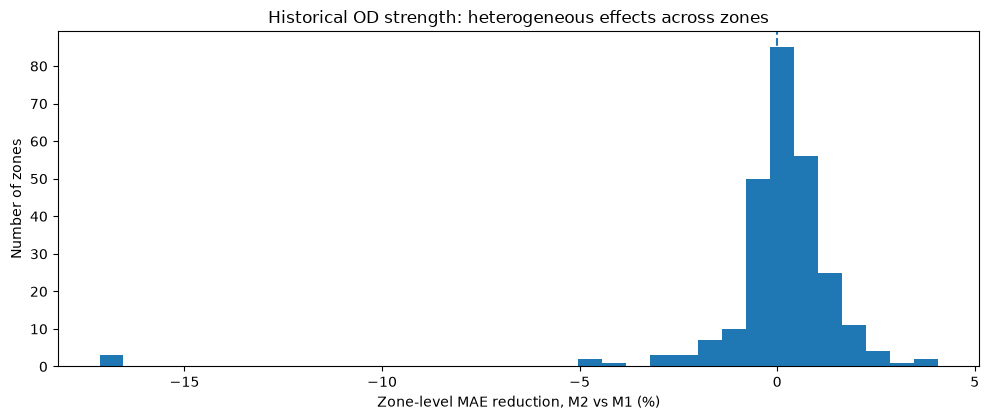

In [10]:
d = prediction_test.copy()
d["abs_err_m1"] = (d[TARGET]-d["pred_m1"]).abs()
d["abs_err_m2"] = (d[TARGET]-d["pred_m2"]).abs()
d["abs_err_m4"] = (d[TARGET]-d["pred_m4"]).abs()
d["gain_m2_vs_m1"] = d["abs_err_m1"]-d["abs_err_m2"]
zone_result = (d.groupby("zone_id", observed=True)
               .agg(n_obs=(TARGET,"size"), mean_pickups=(TARGET,"mean"),
                    MAE_M1=("abs_err_m1","mean"), MAE_M2=("abs_err_m2","mean"),
                    MAE_M4=("abs_err_m4","mean"))
               .reset_index())
zone_result["MAE_reduction_pct"] = np.where(zone_result.MAE_M1 > 0,
    100*(zone_result.MAE_M1-zone_result.MAE_M2)/zone_result.MAE_M1,np.nan)
print("Zones improved (M2 vs M1):", int((zone_result.MAE_M2 < zone_result.MAE_M1).sum()),
      "of",len(zone_result))
display(zone_result.sort_values("MAE_reduction_pct", ascending=False).head(12).round(3))
display(zone_result.sort_values("MAE_reduction_pct").head(12).round(3))
fig, ax = plt.subplots(figsize=(10,4.3))
ax.hist(zone_result["MAE_reduction_pct"].dropna(), bins=35)
ax.axvline(0, linestyle="--")
ax.set(xlabel="Zone-level MAE reduction, M2 vs M1 (%)", ylabel="Number of zones",
       title="Historical OD strength: heterogeneous effects across zones")
fig.tight_layout()
fig.savefig(OUT/"zone_mae_reduction_hist.png", dpi=160)
plt.show()


 Training-demand level


/var/folders/ww/5mshxs8524ngyq_y2qdc9t9c0000gn/T/ipykernel_91678/127075189.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["is_weekend"] = d["pickup_hour"].dt.dayofweek >= 5


,demand_level,n_obs,MAE_M1,MAE_M2,MAE_M4,MAE_reduction_pct
0,High,113960,9.262,9.224,9.241,0.402
1,Low,113960,0.375,0.374,0.375,0.191
2,Medium,112665,1.229,1.229,1.232,-0.026



 Hour


,hour,n_obs,MAE_M1,MAE_M2,MAE_M4,MAE_reduction_pct
0,0,14202,3.666,3.670,3.670,-0.105
1,1,13939,2.675,2.665,2.687,0.364
2,2,14202,1.989,1.996,1.994,-0.356
3,3,14202,1.548,1.565,1.561,-1.097
4,4,14202,1.521,1.526,1.516,-0.339
5,5,14202,1.618,1.617,1.610,0.048
6,6,14202,2.336,2.340,2.340,-0.178
7,7,14202,3.457,3.458,3.497,-0.028
8,8,14202,3.644,3.652,3.652,-0.209
9,9,14202,3.371,3.381,3.406,-0.290



 Weekend


,is_weekend,n_obs,MAE_M1,MAE_M2,MAE_M4,MAE_reduction_pct
0,False,239856,3.595,3.576,3.583,0.525
1,True,100729,3.716,3.718,3.727,-0.063


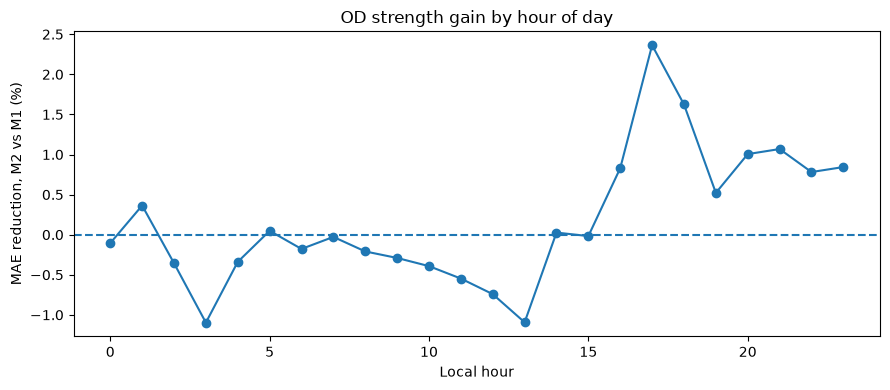

In [11]:
# Train-defined demand bins (avoid defining groups from test targets)
train_zone_mean = SPLITS["Train"].groupby("zone_id", observed=True)[TARGET].mean()
train_zone_mean.index = train_zone_mean.index.astype(int)
# rank(method='first') handles repeated zero-demand means without dropping zones
rank = train_zone_mean.rank(method="first")
bins = pd.qcut(rank, q=3, labels=["Low", "Medium", "High"])
d["demand_level"] = d["zone_id"].map(bins.to_dict())
d["hour"] = d["pickup_hour"].dt.hour
d["is_weekend"] = d["pickup_hour"].dt.dayofweek >= 5

def group_gain(frame, group):
    s = frame.groupby(group, observed=True).agg(
        n_obs=(TARGET,"size"), MAE_M1=("abs_err_m1","mean"),
        MAE_M2=("abs_err_m2","mean"), MAE_M4=("abs_err_m4","mean")
    ).reset_index()
    s["MAE_reduction_pct"] = 100*(s.MAE_M1-s.MAE_M2)/s.MAE_M1.replace(0,np.nan)
    return s

by_demand = group_gain(d,"demand_level")
by_hour = group_gain(d,"hour")
by_weekend = group_gain(d,"is_weekend")
for title, frame in [("Training-demand level",by_demand), ("Hour",by_hour),
                     ("Weekend",by_weekend)]:
    print("\n",title)
    display(frame.round(3))
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(by_hour["hour"],by_hour["MAE_reduction_pct"],marker="o")
ax.axhline(0,linestyle="--")
ax.set(xlabel="Local hour",ylabel="MAE reduction, M2 vs M1 (%)",
       title="OD strength gain by hour of day")
fig.tight_layout()
fig.savefig(OUT/"hourly_mae_reduction.png",dpi=160)
plt.show()

## 9. Uncertainty: Paired Daily Block Bootstrap (Descriptive)

Use daily blocks of hourly zone-level **absolute-error differences**, preserving correlation among zones within each day. Re-sample days with replacement and recompute observation-weighted mean loss difference. This is a descriptive uncertainty check, not a proof of causal effect or a replacement for multiple independent temporal test periods. An already-reused test set limits confirmatory interpretation.

In [12]:
# Compute daily totals and observation counts to avoid large bootstrap allocations
d["date"] = d["pickup_hour"].dt.date
daily = d.groupby("date", observed=True).agg(
    gain_sum=("gain_m2_vs_m1","sum"), n_obs=("gain_m2_vs_m1","size")
).reset_index()
rg = np.random.default_rng(RANDOM_SEED)
B = 2000
ix = rg.integers(0, len(daily), size=(B,len(daily)))
sums = daily["gain_sum"].to_numpy()[ix].sum(axis=1)
ns = daily["n_obs"].to_numpy()[ix].sum(axis=1)
boot = sums/ns
lo, hi = np.quantile(boot,[0.025,0.975])
observed = float(d["gain_m2_vs_m1"].mean())
print(f"M2 minus M1 absolute-error reduction (positive is better): {observed:.6f} pickups/zone-hour")
print(f"Daily-block bootstrap 95% interval: [{lo:.6f}, {hi:.6f}]")
print("Independent time period and non-adaptive holdout required for confirmatory claims.")

M2 minus M1 absolute-error reduction (positive is better): 0.012588 pickups/zone-hour
Daily-block bootstrap 95% interval: [0.001690, 0.024703]
Independent time period and non-adaptive holdout required for confirmatory claims.


## 10. Final Artifacts, Experiment Manifest and Reproducibility

Persist the exact models used for final predictions, **including best iterations**, feature sets, all prediction vectors, test/validation reports, and run configuration. This supersedes the previous notebook's `zone_temporal_model_tuned` artifact. The output folder is relative to `PROJECT_ROOT`, never to the Notebook working directory.

In [13]:
for name, model in final_models.items():
    code_name = name.split()[0].lower()
    joblib.dump(model, OUT/f"{code_name}_final.joblib")

prediction_test.to_parquet(OUT/"test_predictions.parquet",index=False)
prediction_val.to_parquet(OUT/"validation_predictions.parquet",index=False)
all_results.to_csv(OUT/"all_metrics.csv",index=False)
gain_table.to_csv(OUT/"rq3_gain_table.csv",index=False)
zone_result.to_csv(OUT/"per_zone_mae.csv",index=False)
by_demand.to_csv(OUT/"by_train_demand_level.csv",index=False)
by_hour.to_csv(OUT/"by_hour.csv",index=False)
by_weekend.to_csv(OUT/"by_weekend.csv",index=False)
objective_results_df.to_csv(OUT/"objective_validation.csv",index=False)
pd.DataFrame(validation_rows).to_csv(OUT/"temporal_validation.csv",index=False)
pd.DataFrame(source_report).to_csv(OUT/"monthly_source_audit.csv",index=False)

manifest = {
    "forecast_contract":"rolling one-hour-ahead, local naive NYC time",
    "data_scope":"2025 cleaned NYC yellow taxi pickup records; 263 selected zones",
    "network_data":str(AUG_FILE.relative_to(PROJECT_ROOT)),
    "train_end_exclusive":str(TRAIN_END), "validation_end_exclusive":str(VAL_END),
    "DST_exclusion":"Transition hour through +168h inclusive",
    "fast_mode": FAST_MODE,
    "random_seed": RANDOM_SEED,
    "max_estimators": MAX_ESTIMATORS,
    "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
    "early_stopping_metric":"l1 (unclipped predictions)",
    "selected_temporal":selected_temporal,
    "selected_objective":selected_objective,
    "params":BASE_PARAMS,
    "feature_sets":FEATURE_SETS,
    "best_iterations":{k:int(m.best_iteration_) for k,m in final_models.items()},
    "split_counts":{k:len(v) for k,v in SPLITS.items()},
    "versions":{"python":platform.python_version(),"pandas":pd.__version__,
                "lightgbm":lgb.__version__},
    "disclosure":"Nov-Dec test was consulted in prior exploratory iterations; not a pristine untouched holdout.",
}
with open(OUT/"experiment_manifest.json","w",encoding="utf-8") as f:
    json.dump(manifest,f,ensure_ascii=False,indent=2)
print("Saved final artifacts to:",OUT)
print("Files:",*[x.name for x in sorted(OUT.iterdir())],sep="\n - ")

Saved final artifacts to: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining/results/forecasting/final_rq3
Files:
 - all_metrics.csv
 - by_hour.csv
 - by_train_demand_level.csv
 - by_weekend.csv
 - experiment_manifest.json
 - hourly_mae_reduction.png
 - m0_final.joblib
 - m1_final.joblib
 - m2_final.joblib
 - m3_final.joblib
 - m4_final.joblib
 - monthly_source_audit.csv
 - objective_validation.csv
 - per_zone_mae.csv
 - rq3_gain_table.csv
 - temporal_validation.csv
 - test_predictions.parquet
 - validation_predictions.parquet
 - zone_mae_reduction_hist.png


## 11. Results and Interpretation — Initial Forecasting

### Key Findings

This notebook establishes a reproducible forecasting pipeline for hourly NYC Yellow Taxi pickup demand using a common zone-hour modeling sample and chronological train, validation, and test splits.

**Finding 1 — Historical demand features substantially improve forecasting accuracy.**

The temporal LightGBM model (M1) achieves a test MAE of 3.6308, compared with 6.2210 for the calendar-only model (M0), representing a 41.6% reduction in MAE. Historical pickup lags and rolling averages are therefore essential predictors of hourly demand.

**Finding 2 — Poisson LightGBM performs best on validation MAE among the evaluated objectives.**

Poisson regression achieves a validation MAE of 3.3781, compared with 3.3931 for standard regression and 3.8953 for L1 regression, using the original temporal features.

**Finding 3 — Historical OD strength provides a modest improvement.**

Adding historical OD strength features reduces test MAE from 3.6308 (M1) to 3.6182 (M2), an improvement of approximately 0.347%. M2 also achieves the lowest test RMSE of 10.2988.

**Finding 4 — Additional network topology features do not improve overall performance.**

Adding degree and subsequently HHI-related features does not outperform M2. This indicates that more detailed network summaries do not necessarily provide greater incremental predictive value under the current model configuration.

**Finding 5 — Network benefits are spatially heterogeneous.**

M2 improves prediction MAE in 164 of 263 zones (62.4%) on the test period. However, the magnitude and direction of improvement vary substantially across zones.

### Interpretation

Historical temporal demand patterns explain most of the predictive improvement. Historical OD network strength provides additional but limited predictive information, while degree and flow concentration do not improve overall accuracy in the initial experiments.

### Limitations

The models use a 3,000-round training cap, with several models reaching their best iteration near that limit. The initial feature comparison also selects temporal features under standard regression before comparing objectives.

Furthermore, the November–December test period was examined during exploratory development. Subsequent model selection should therefore rely on validation data, and earlier test results should be interpreted with this limitation in mind.

### Conclusion

The initial results establish OD Strength as the strongest network feature block and motivate further investigation of temporal feature design, boosting convergence, and the stability of network-related improvements.